# Exploratory Data Analysis (EDA) for Data Warehouse Global Online Retail
---

## วัตถุประสงค์ของการทำ Exploratory Data Analysis (EDA)
1. **สำรวจโครงสร้างและคุณภาพของข้อมูล (Data Profiling & Quality Assessment):** ตรวจสอบค่าสูญหาย (Missing Values), ข้อมูลซ้ำ (Duplicates), ความถูกต้องของชนิดข้อมูล และค่าผิดปกติ (Outliers)
2. **วิเคราะห์พฤติกรรมของตัวแปรหลัก (Univariate & Multivariate Analysis):** เจาะลึกปริมาณการซื้อขาย (Quantity), ระดับราคา (Price), แนวโน้มตามช่วงเวลา (Time Trends), และการกระจายตัวเชิงภูมิศาสตร์ (Geography)
3. **วิเคราะห์พฤติกรรมการคืนสินค้า (Return & Cancellation Analysis):** ค้นหาสาเหตุและมูลค่าการคืนสินค้า (Return Loss) เพื่อระบุสินค้าหรือตลาดที่มีความเสี่ยงสูง
4. **จัดกลุ่มพฤติกรรมลูกค้า (Customer RFM Segmentation):** วิเคราะห์ Recency, Frequency, Monetary เพื่อแบ่งกลุ่มลูกค้าเชิงกลยุทธ์
5. **วางรากฐานการออกแบบ Dimensional Modeling (Kimball Star Schema):** นำผลลัพธ์จากการสำรวจไปกำหนด Fact Tables, Grain, Dimensions และ Aggregation Tables สำหรับ Data Warehouse


## 1. การติดตั้งและนำเข้าไลบรารีที่จำเป็น (Environment Setup & Imports)


In [1]:
import os
import sys
import warnings
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ตั้งค่าการแสดงผล
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Tahoma']
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 50)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("Numpy version:", np.__version__)


Libraries imported successfully!
Pandas version: 3.1.1
Numpy version: 2.5.5


## 2. การโหลดข้อมูลและสำรวจโครงสร้างเบื้องต้น (Data Loading & Initial Profiling)
โหลดไฟล์ข้อมูล `Sales Transaction v.4a.csv` ซึ่งบันทึกประวัติการสั่งซื้อสินค้าระดับ Line-item


In [2]:
# กำหนด Path ไฟล์ข้อมูล
csv_path = os.path.join("data", "Sales Transaction v.4a.csv")
if not os.path.exists(csv_path):
    csv_path = "Sales Transaction v.4a.csv"

# โหลดข้อมูล
df = pd.read_csv(csv_path)

print(f"ขนาดของชุดข้อมูล (Shape): {df.shape[0]:,} แถว, {df.shape[1]} คอลัมน์")
df.head(5)


ขนาดของชุดข้อมูล (Shape): 536,350 แถว, 8 คอลัมน์


,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country
0,581482,12/9/2019,22485,Set Of 2 Wooden Market Crates,21.47,12,17490.00,United Kingdom
1,581475,12/9/2019,22596,Christmas Star Wish List Chalkboard,10.65,36,13069.00,United Kingdom
2,581475,12/9/2019,23235,Storage Tin Vintage Leaf,11.53,12,13069.00,United Kingdom
3,581475,12/9/2019,23272,Tree T-Light Holder Willie Winkie,10.65,12,13069.00,United Kingdom
4,581475,12/9/2019,23239,Set Of 4 Knick Knack Tins Poppies,11.94,6,13069.00,United Kingdom


In [3]:
# ตรวจสอบชนิดข้อมูลและภาพรวมคอลัมน์
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 536350 entries, 0 to 536349
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionNo  536350 non-null  str    
 1   Date           536350 non-null  str    
 2   ProductNo      536350 non-null  str    
 3   ProductName    536350 non-null  str    
 4   Price          536350 non-null  float64
 5   Quantity       536350 non-null  int64  
 6   CustomerNo     536295 non-null  float64
 7   Country        536350 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 63.4 MB


## 3. การประเมินคุณภาพข้อมูล (Data Quality Assessment)
ตรวจสอบค่าว่าง (Missing Values), ข้อมูลซ้ำซ้อน (Duplicates) และความผิดปกติในชุดข้อมูล


In [4]:
# 1. ตรวจสอบ Missing Values
missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df)) * 100
})
missing_df['Data Type'] = df.dtypes
print("=== สรุปค่าสูญหาย (Missing Values) ===")
print(missing_df.sort_values(by='Missing Count', ascending=False))

# 2. ตรวจสอบข้อมูลซ้ำซ้อน (Duplicates)
duplicate_count = df.duplicated().sum()
print(f"\nจำนวนแถวที่ซ้ำกันทั้งหมด (Exact Duplicates): {duplicate_count:,} แถว ({duplicate_count/len(df)*100:.2f}%)")


=== สรุปค่าสูญหาย (Missing Values) ===
               Missing Count  Missing % Data Type
CustomerNo                55       0.01   float64
TransactionNo              0       0.00       str
ProductNo                  0       0.00       str
Date                       0       0.00       str
ProductName                0       0.00       str
Price                      0       0.00   float64
Quantity                   0       0.00     int64
Country                    0       0.00       str



จำนวนแถวที่ซ้ำกันทั้งหมด (Exact Duplicates): 5,200 แถว (0.97%)


In [5]:
# การทำ Data Cleaning ขั้นต้น:
# 1. ลบรายการซ้ำซ้อน (Exact duplicates)
df_clean = df.drop_duplicates().copy()

# 2. แปลงฟิลด์ Date ให้อยู่ในรูปแบบ datetime
df_clean['Date'] = pd.to_datetime(df_clean['Date'], format='%m/%d/%Y', errors='coerce')

# 3. จัดการ CustomerNo ที่เป็นค่าว่าง (Guest Customers)
# กำหนดรหัส 99999 สำหรับ Guest/Unregistered Transactions เพื่อรักษา Referential Integrity ใน Data Warehouse
df_clean['CustomerNo_Filled'] = df_clean['CustomerNo'].fillna(99999).astype(int)

# 4. ตรวจสอบ Transaction ที่เป็นการยกเลิก/คืนสินค้า (ขึ้นต้นด้วย 'C')
df_clean['Is_Cancellation'] = df_clean['TransactionNo'].astype(str).str.startswith('C')

print(f"ข้อมูลหลังคลีนเบื้องต้นคงเหลือ: {len(df_clean):,} แถว")
df_clean.head(3)


ข้อมูลหลังคลีนเบื้องต้นคงเหลือ: 531,150 แถว


,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country,CustomerNo_Filled,Is_Cancellation
0,581482,2019-12-09,22485,Set Of 2 Wooden Market Crates,21.47,12,17490.00,United Kingdom,17490,False
1,581475,2019-12-09,22596,Christmas Star Wish List Chalkboard,10.65,36,13069.00,United Kingdom,13069,False
2,581475,2019-12-09,23235,Storage Tin Vintage Leaf,11.53,12,13069.00,United Kingdom,13069,False


## 4. การวิเคราะห์ตัวแปรเดี่ยว (Univariate Analysis)
สำรวจสถิติเชิงพรรณนาและการกระจายตัวของตัวแปรแต่ละตัว ทั้งเชิงปริมาณ (Quantity, Price) และเชิงกลุ่ม (TransactionNo, Country, ProductNo)


In [6]:
# สถิติเชิงพรรณนาของตัวแปรเชิงตัวเลข
df_clean[['Quantity', 'Price']].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])


,Quantity,Price
count,531150.00,531150.00
mean,9.99,12.67
std,217.70,8.53
min,-80995.00,5.13
1%,-1.00,5.97
5%,1.00,6.19
25%,1.00,10.99
50%,3.00,11.94
75%,10.00,14.09
95%,30.00,19.42


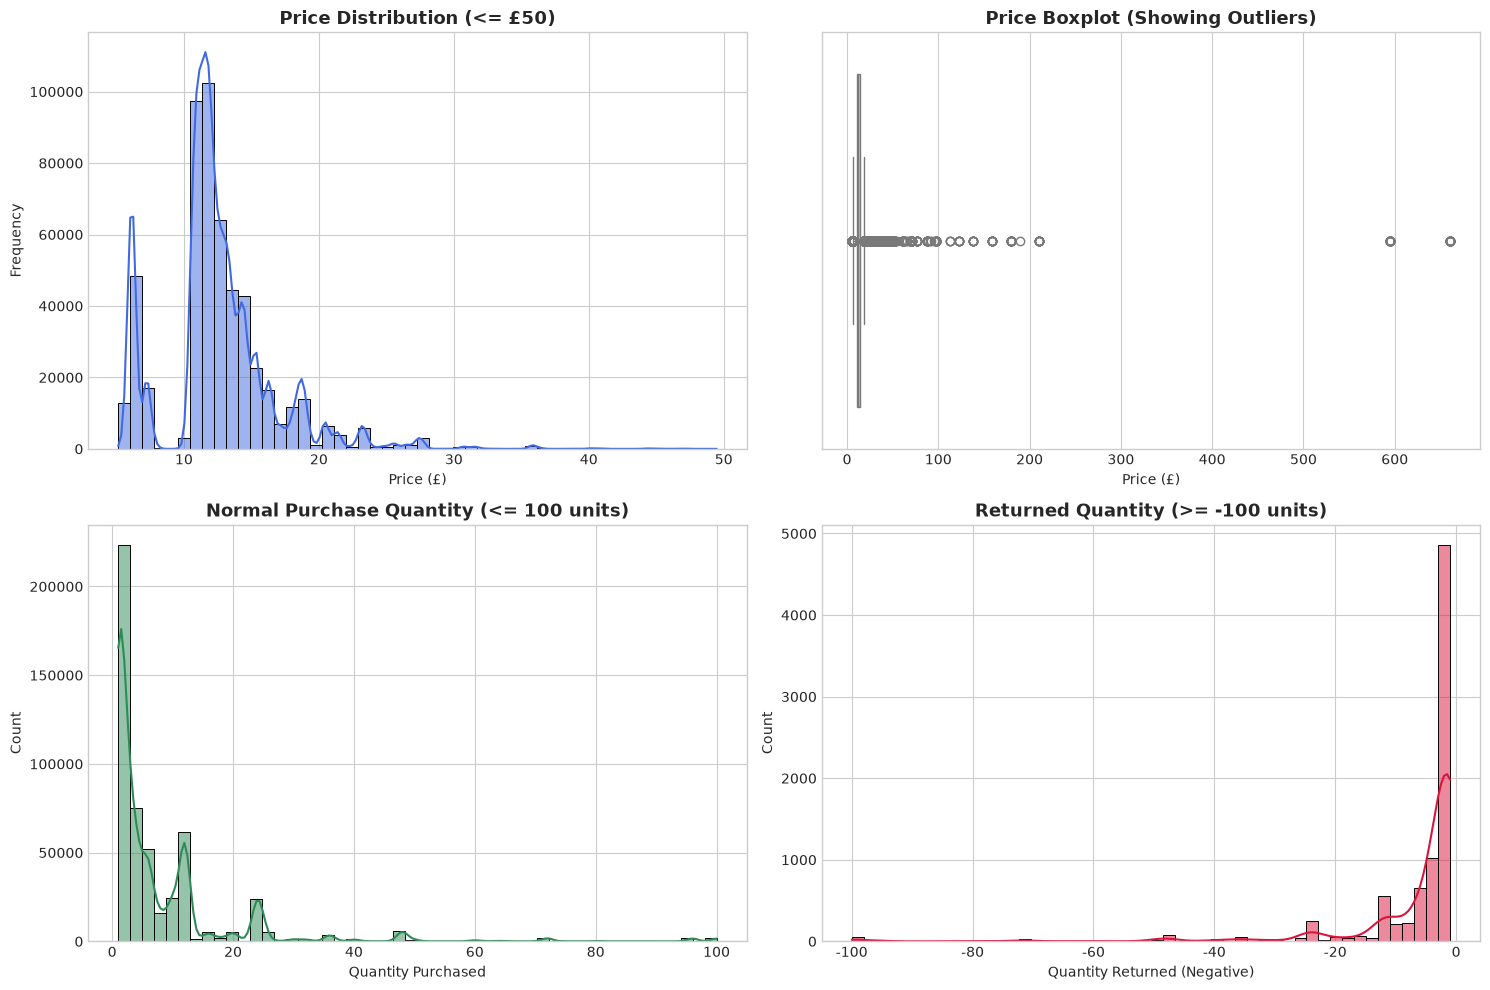

In [7]:
# พล็อตการกระจายตัวของ Price และ Quantity
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. การกระจายตัวของ Price (เฉพาะช่วง 0 - 50 GBP เพื่อเห็นภาพชัดเจน)
sns.histplot(df_clean[df_clean['Price'] <= 50]['Price'], bins=50, kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title('Price Distribution (<= £50)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Price (£)')
axes[0, 0].set_ylabel('Frequency')

# 2. Boxplot ของ Price
sns.boxplot(x=df_clean['Price'], ax=axes[0, 1], color='lightblue')
axes[0, 1].set_title('Price Boxplot (Showing Outliers)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Price (£)')

# 3. Quantity Distribution (แยกยอดซื้อปกติ > 0 และ ยอดคืน < 0)
normal_qty = df_clean[df_clean['Quantity'] > 0]['Quantity']
sns.histplot(normal_qty[normal_qty <= 100], bins=50, kde=True, ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Normal Purchase Quantity (<= 100 units)', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Quantity Purchased')

# 4. Return Quantity Distribution (< 0)
return_qty = df_clean[df_clean['Quantity'] < 0]['Quantity']
sns.histplot(return_qty[return_qty >= -100], bins=50, kde=True, ax=axes[1, 1], color='crimson')
axes[1, 1].set_title('Returned Quantity (>= -100 units)', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Quantity Returned (Negative)')

plt.tight_layout()
plt.show()


## 5. การสกัดและสร้างคุณลักษณะใหม่ (Feature Engineering)
คำนวณตัวชี้วัดทางการเงิน (Gross Sales, Return Loss, Net Revenue), มิติเวลา (Date Dimensions) และการจัดหมวดหมู่สินค้าอัตโนมัติ (Product Categorization)


In [8]:
# 1. คำนวณยอดเงิน Gross Amount, Return Amount และ Net Amount
df_clean['Gross_Amount'] = np.where(df_clean['Quantity'] > 0, df_clean['Quantity'] * df_clean['Price'], 0.0)
df_clean['Return_Amount'] = np.where(df_clean['Quantity'] < 0, np.abs(df_clean['Quantity']) * df_clean['Price'], 0.0)
df_clean['Net_Amount'] = df_clean['Quantity'] * df_clean['Price']

# 2. สกัดฟีเจอร์มิติเวลา (Time Dimensions)
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Month'] = df_clean['Date'].dt.month
df_clean['Quarter'] = df_clean['Date'].dt.quarter
df_clean['YearMonth'] = df_clean['Date'].dt.strftime('%Y-%m')
df_clean['DayOfWeek'] = df_clean['Date'].dt.day_name()
df_clean['DayOfWeek_Num'] = df_clean['Date'].dt.dayofweek # 0=Monday, 6=Sunday
df_clean['Is_Weekend'] = df_clean['DayOfWeek_Num'].isin([5, 6]).astype(int)

# 3. จัดหมวดหมู่สินค้าด้วย Keyword Matching (8 Product Categories)
def categorize_product(name):
    if not isinstance(name, str):
        return 'Gifts & General Merchandise'
    n = name.upper()
    if any(k in n for k in ['CHRISTMAS', 'HOLIDAY', 'EASTER', 'HALLOWEEN', 'XMAS', 'DECORATION', 'WREATH', 'BUNTING', 'T-LIGHT', 'CANDLE', 'RIBBON']):
        return 'Holiday & Seasonal'
    elif any(k in n for k in ['BAG', 'TOTE', 'LUGGAGE', 'PURSE', 'BACKPACK', 'SHOPPER', 'WALLET']):
        return 'Bags & Luggage'
    elif any(k in n for k in ['BOX', 'TIN', 'STORAGE', 'DRAWER', 'BASKET', 'CHEST', 'CASE', 'JAR']):
        return 'Home Storage & Containers'
    elif any(k in n for k in ['MUG', 'CUP', 'BOWL', 'PLATE', 'TEAPOT', 'KITCHEN', 'BAKE', 'CUTLERY', 'GLASS', 'DISH', 'BOTTLE', 'SPOON', 'FORK', 'LUNCH']):
        return 'Kitchen & Dining'
    elif any(k in n for k in ['SIGN', 'CLOCK', 'FRAME', 'MIRROR', 'VINTAGE', 'HEART', 'WALL', 'HANGER', 'HOOK', 'CUSHION', 'DOORMAT']):
        return 'Home Decor & Furnishing'
    elif any(k in n for k in ['TOY', 'GAME', 'MARBLES', 'DOLL', 'CHILD', 'BABY', 'PUZZLE', 'PLAY', 'LOLA']):
        return 'Toys & Children'
    elif any(k in n for k in ['PEN', 'PENCIL', 'NOTEBOOK', 'CARD', 'STICKER', 'PAPER', 'TAPE', 'STAMP', 'WRAP', 'BOOK']):
        return 'Stationery & Papercraft'
    elif any(k in n for k in ['SOAP', 'LAVENDER', 'BATH', 'LIP', 'CREAM', 'TOWEL']):
        return 'Bath & Beauty'
    else:
        return 'Gifts & General Merchandise'

df_clean['Product_Category'] = df_clean['ProductName'].apply(categorize_product)

print("=== สรุปภาพรวมทางการเงิน (Overall Financial Summary) ===")
print(f"ยอดขายขั้นต้น (Gross Revenue): £{df_clean['Gross_Amount'].sum():,.2f}")
print(f"มูลค่าสินค้าที่ถูกคืน (Return Loss): £{df_clean['Return_Amount'].sum():,.2f}")
print(f"รายได้สุทธิรวม (Net Revenue): £{df_clean['Net_Amount'].sum():,.2f}")
print(f"อัตราการคืนสินค้าโดยรวม (Return Rate): {df_clean['Return_Amount'].sum() / df_clean['Gross_Amount'].sum() * 100:.2f}%")


=== สรุปภาพรวมทางการเงิน (Overall Financial Summary) ===
ยอดขายขั้นต้น (Gross Revenue): £62,781,386.54
มูลค่าสินค้าที่ถูกคืน (Return Loss): £2,664,628.15
รายได้สุทธิรวม (Net Revenue): £60,116,758.39
อัตราการคืนสินค้าโดยรวม (Return Rate): 4.24%


## 6. การวิเคราะห์ตัวแปรคู่และความสัมพันธ์ (Bivariate & Multivariate Analysis)
เจาะลึกมิติเวลา (Time Series), ภูมิศาสตร์ (Geographical), การกระจายตามหมวดหมู่สินค้า และหลักการ Pareto (80/20 Rule)


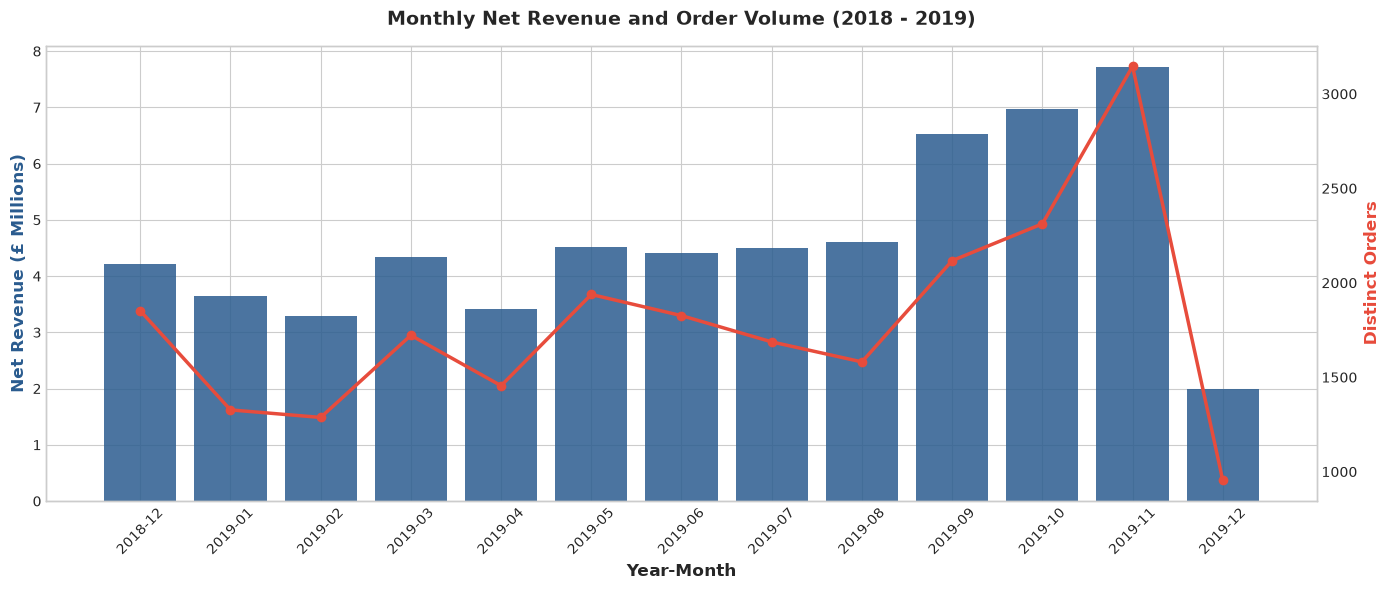

In [9]:
# 1. วิเคราะห์แนวโน้มยอดขายรายเดือน (Monthly Revenue Trend)
monthly_perf = df_clean.groupby('YearMonth').agg(
    Gross_Revenue=('Gross_Amount', 'sum'),
    Return_Loss=('Return_Amount', 'sum'),
    Net_Revenue=('Net_Amount', 'sum'),
    Orders_Count=('TransactionNo', 'nunique')
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.bar(monthly_perf['YearMonth'], monthly_perf['Net_Revenue']/1e6, color='#2b5c8f', alpha=0.85, label='Net Revenue (£ Millions)')
ax1.set_ylabel('Net Revenue (£ Millions)', fontsize=12, fontweight='bold', color='#2b5c8f')
ax1.set_xlabel('Year-Month', fontsize=12, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
ax2.plot(monthly_perf['YearMonth'], monthly_perf['Orders_Count'], color='#e74c3c', marker='o', linewidth=2.5, label='Order Count')
ax2.set_ylabel('Distinct Orders', fontsize=12, fontweight='bold', color='#e74c3c')
ax2.grid(False)

plt.title('Monthly Net Revenue and Order Volume (2018 - 2019)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()


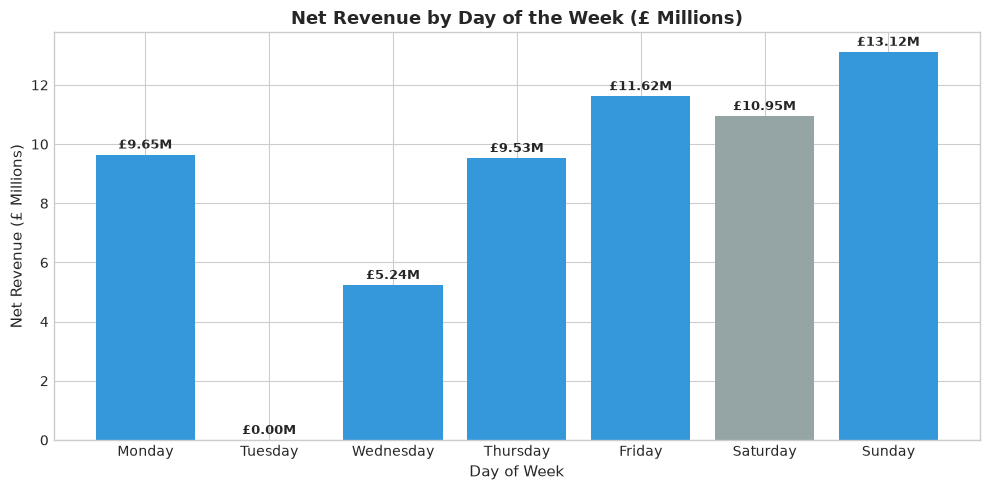

In [10]:
# 2. วิเคราะห์ยอดขายตามวันในสัปดาห์ (Day of Week Analysis)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_perf = df_clean.groupby('DayOfWeek').agg(
    Net_Revenue=('Net_Amount', 'sum'),
    Transactions=('TransactionNo', 'nunique')
).reindex(day_order).fillna(0).reset_index()

plt.figure(figsize=(10, 5))
bars = plt.bar(day_perf['DayOfWeek'], day_perf['Net_Revenue']/1e6, color=['#3498db' if d != 'Saturday' else '#95a5a6' for d in day_perf['DayOfWeek']])
plt.title('Net Revenue by Day of the Week (£ Millions)', fontsize=13, fontweight='bold')
plt.xlabel('Day of Week', fontsize=11)
plt.ylabel('Net Revenue (£ Millions)', fontsize=11)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f'£{yval:.2f}M', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


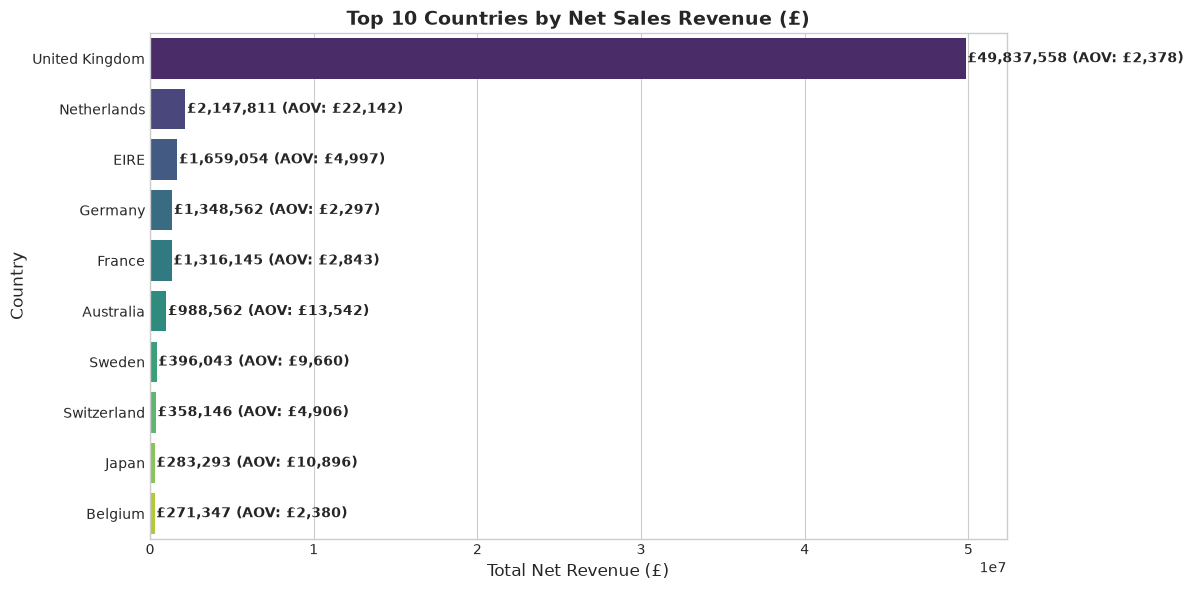

In [11]:
# 3. วิเคราะห์ตลาดต่างประเทศ 10 อันดับแรก (Top 10 Export Markets by Net Sales)
top_countries = df_clean.groupby('Country').agg(
    Net_Revenue=('Net_Amount', 'sum'),
    Orders=('TransactionNo', 'nunique'),
    Total_Units=('Quantity', 'sum')
).sort_values(by='Net_Revenue', ascending=False).head(10).reset_index()

top_countries['AOV'] = top_countries['Net_Revenue'] / top_countries['Orders']

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=top_countries, x='Net_Revenue', y='Country', palette='viridis', ax=ax)
ax.set_title('Top 10 Countries by Net Sales Revenue (£)', fontsize=14, fontweight='bold')
ax.set_xlabel('Total Net Revenue (£)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)

# ใส่ตัวเลขแสดงมูลค่า
for i, v in enumerate(top_countries['Net_Revenue']):
    ax.text(v + 100000, i, f"£{v:,.0f} (AOV: £{top_countries.loc[i, 'AOV']:,.0f})", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


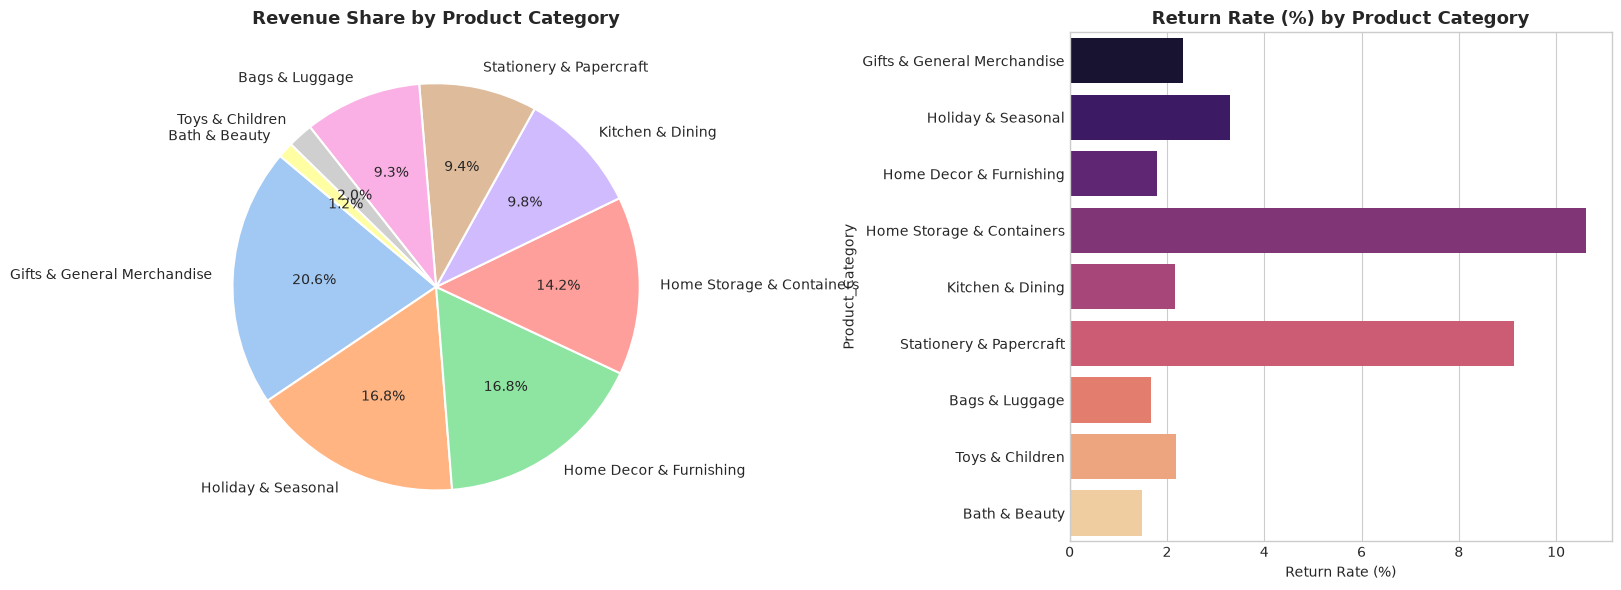

In [12]:
# 4. การกระจายตามหมวดหมู่สินค้า (Product Category Breakdown)
cat_summary = df_clean.groupby('Product_Category').agg(
    Net_Revenue=('Net_Amount', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Return_Loss=('Return_Amount', 'sum')
).sort_values(by='Net_Revenue', ascending=False).reset_index()

cat_summary['Return_Rate_%'] = (cat_summary['Return_Loss'] / (cat_summary['Net_Revenue'] + cat_summary['Return_Loss'])) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# กราฟโดนัทแสดงสัดส่วนรายได้ตามหมวดหมู่
axes[0].pie(cat_summary['Net_Revenue'], labels=cat_summary['Product_Category'], autopct='%1.1f%%',
            startangle=140, colors=sns.color_palette('pastel'), wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[0].set_title('Revenue Share by Product Category', fontsize=13, fontweight='bold')

# กราฟแท่งแสดง Return Rate ตามหมวดหมู่สินค้า
sns.barplot(data=cat_summary, x='Return_Rate_%', y='Product_Category', palette='magma', ax=axes[1])
axes[1].set_title('Return Rate (%) by Product Category', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Return Rate (%)')

plt.tight_layout()
plt.show()


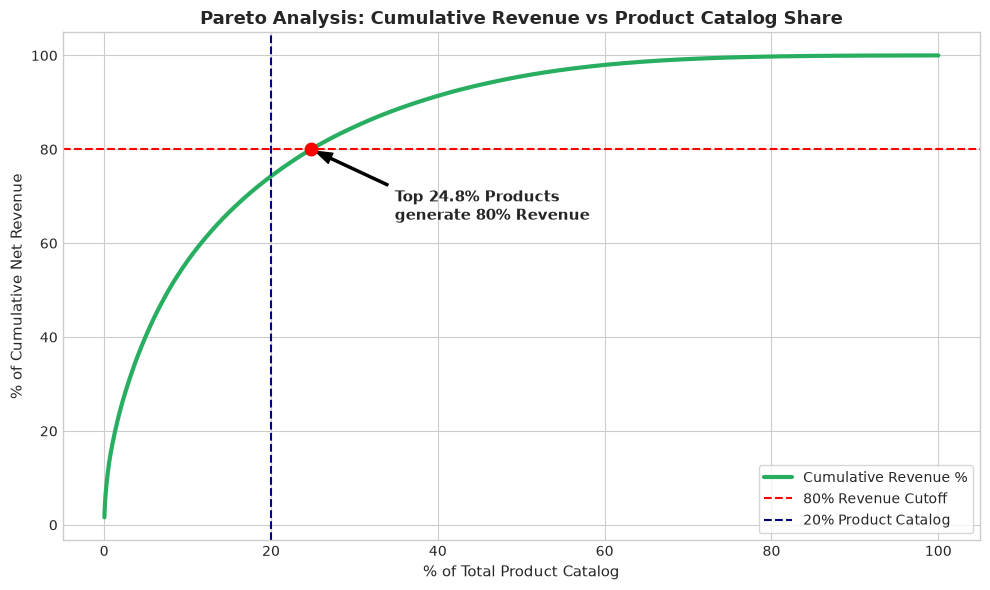

In [13]:
# 5. กฎพาเรโต 80/20 (Pareto Principle Analysis on Products)
prod_sales = df_clean[df_clean['Net_Amount'] > 0].groupby('ProductNo')['Net_Amount'].sum().sort_values(ascending=False).reset_index()
prod_sales['Cumulative_Revenue'] = prod_sales['Net_Amount'].cumsum()
prod_sales['Cumulative_Pct'] = (prod_sales['Cumulative_Revenue'] / prod_sales['Net_Amount'].sum()) * 100
prod_sales['Product_Rank_Pct'] = ((prod_sales.index + 1) / len(prod_sales)) * 100

plt.figure(figsize=(10, 6))
plt.plot(prod_sales['Product_Rank_Pct'], prod_sales['Cumulative_Pct'], color='#27ae60', linewidth=3, label='Cumulative Revenue %')
plt.axhline(80, color='red', linestyle='--', label='80% Revenue Cutoff')
plt.axvline(20, color='navy', linestyle='--', label='20% Product Catalog')

# หาจุดตัดว่าสินค้ากี่ % ทำรายได้ 80%
p80_idx = (prod_sales['Cumulative_Pct'] >= 80).idxmax()
prod_pct_at_80 = prod_sales.loc[p80_idx, 'Product_Rank_Pct']
plt.scatter([prod_pct_at_80], [80], color='red', s=80, zorder=5)
plt.annotate(f'Top {prod_pct_at_80:.1f}% Products\ngenerate 80% Revenue', 
             xy=(prod_pct_at_80, 80), xytext=(prod_pct_at_80 + 10, 65),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, fontweight='bold')

plt.title('Pareto Analysis: Cumulative Revenue vs Product Catalog Share', fontsize=13, fontweight='bold')
plt.xlabel('% of Total Product Catalog', fontsize=11)
plt.ylabel('% of Cumulative Net Revenue', fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


## 7. การวิเคราะห์สาเหตุและสินค้าที่ถูกคืนสูงสุด (Return Root-Cause Analysis)
ตรวจสอบสินค้าที่สร้างผลกระทบต่อกำไรจากยอดการคืนสินค้า (Return Loss) สูงสุด เพื่อนำไปตั้ง Rule แจ้งเตือนคุณภาพ


In [14]:
# ค้นหาสินค้าที่มียอดคืนเงินสูงสุด (Top 10 Return Loss Products)
top_returns = df_clean[df_clean['Quantity'] < 0].groupby(['ProductNo', 'ProductName']).agg(
    Units_Returned=('Quantity', lambda x: np.abs(x.sum())),
    Total_Return_Loss=('Return_Amount', 'sum'),
    Return_Incidents=('TransactionNo', 'count')
).sort_values(by='Total_Return_Loss', ascending=False).head(10).reset_index()

print("=== 10 อันดับสินค้าที่ถูกคืนมูลค่าสูงสุด (Top 10 High-Risk Return Products) ===")
display(top_returns)


=== 10 อันดับสินค้าที่ถูกคืนมูลค่าสูงสุด (Top 10 High-Risk Return Products) ===


,ProductNo,ProductName,Units_Returned,Total_Return_Loss,Return_Incidents
0,23166,Medium Ceramic Top Storage Jar,74494,843277.96,10
1,23843,Paper Craft Little Birdie,80995,501359.05,1
2,84347,Rotating Silver Angels T-Light Hldr,9367,96310.82,3
3,21108,Fairy Cake Flannel Assorted Colour,3150,38921.40,3
4,85123A,Cream Hanging Heart T-Light Holder,2578,33190.99,42
5,21175,Gin And Tonic Diet Metal Sign,2030,24684.61,7
6,22273,Feltcraft Doll Molly,1447,18424.21,6
7,47566B,Tea Time Party Bunting,1424,18376.16,7
8,22423,Regency Cakestand 3 Tier,855,18148.61,180
9,22920,Herb Marker Basil,1527,16508.19,2


## 8. การวิเคราะห์พฤติกรรมลูกค้าและการแบ่งกลุ่ม (Customer RFM Segmentation)
คำนวณ 3 มิติพฤติกรรมลูกค้า:
* **Recency (R):** จำนวนวันนับจากวันที่มีการซื้อสินค้าครั้งล่าสุด จนถึงวันสุดท้ายของชุดข้อมูล (Snapshot Date: 2019-12-09)
* **Frequency (F):** จำนวนคำสั่งซื้อ (Distinct TransactionNo) ที่ซื้อสำเร็จ
* **Monetary (M):** มูลค่ารวมการสั่งซื้อสุทธิ (£)


In [15]:
# คำนวณ RFM สำหรับลูกค้าที่มี CustomerNo (ไม่รวม Guest 99999)
customer_df = df_clean[df_clean['CustomerNo'].notnull()].copy()
snapshot_date = customer_df['Date'].max() + datetime.timedelta(days=1)

rfm = customer_df.groupby('CustomerNo').agg(
    Recency=('Date', lambda x: (snapshot_date - x.max()).days),
    Frequency=('TransactionNo', 'nunique'),
    Monetary=('Net_Amount', 'sum')
).reset_index()

# กรองเฉพาะลูกค้าที่มียอดซื้อสุทธิ > 0
rfm = rfm[rfm['Monetary'] > 0].copy()

# คำนวณคะแนน Quintiles (1 - 5)
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['RFM_Score'] = rfm['R_Score'] * 100 + rfm['F_Score'] * 10 + rfm['M_Score']

# กำหนดกลุ่มลูกค้าเชิงกลยุทธ์ (Customer Segments)
def assign_segment(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'VIP Champions'
    elif f >= 3 and m >= 3:
        return 'Loyal Customers'
    elif r >= 3 and f <= 2:
        return 'Potential Loyalists'
    elif r <= 2 and (f >= 3 or m >= 3):
        return 'At Risk'
    else:
        return 'Lost Customers'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)

# สรุปภาพรวมของแต่ละ Segment
segment_summary = rfm.groupby('Segment').agg(
    Customer_Count=('CustomerNo', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).reset_index()

segment_summary['Customer_Pct'] = (segment_summary['Customer_Count'] / len(rfm)) * 100
segment_summary['Revenue_Pct'] = (segment_summary['Total_Revenue'] / rfm['Monetary'].sum()) * 100
segment_summary = segment_summary.sort_values(by='Total_Revenue', ascending=False)

print("=== สรุปการจัดกลุ่มลูกค้า (RFM Customer Segments Summary) ===")
display(segment_summary)


=== สรุปการจัดกลุ่มลูกค้า (RFM Customer Segments Summary) ===


,Segment,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Pct,Revenue_Pct
4,VIP Champions,975,12.65,13.27,38344.74,37386117.60,20.72,62.16
2,Loyal Customers,1290,75.78,4.75,11656.74,15037189.16,27.42,25.00
0,At Risk,557,190.23,1.99,5674.35,3160610.41,11.84,5.25
3,Potential Loyalists,704,36.66,1.34,4006.57,2820625.87,14.96,4.69
1,Lost Customers,1179,175.25,1.69,1478.28,1742897.93,25.06,2.90


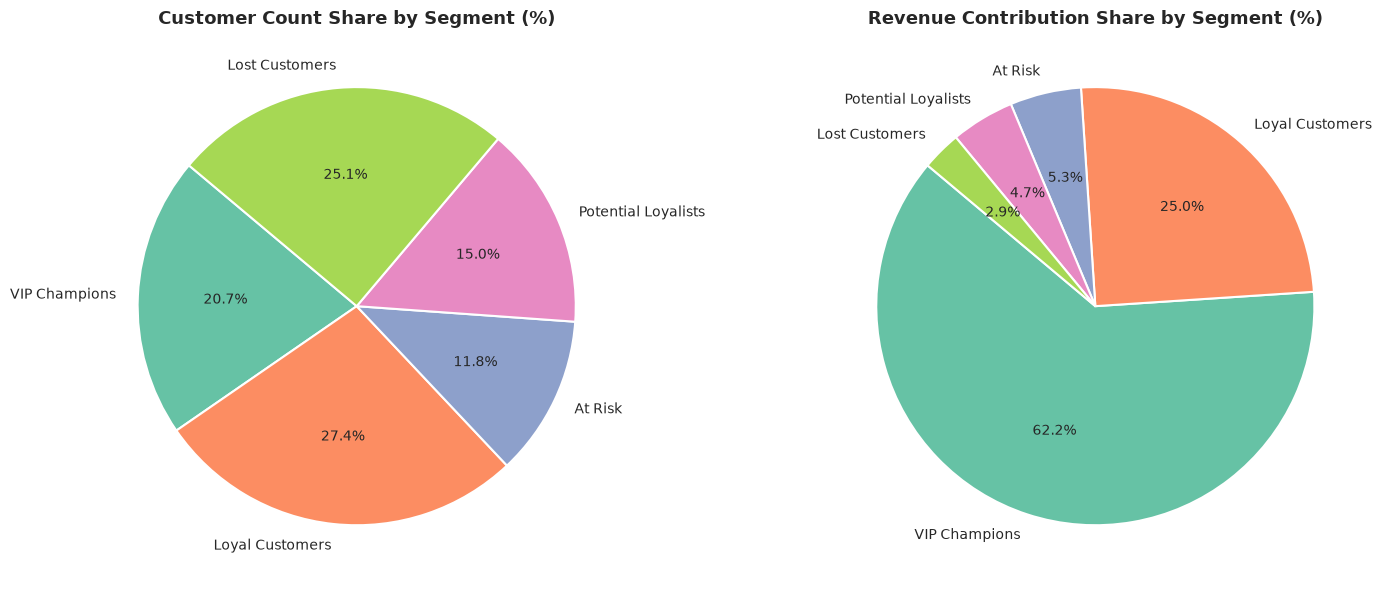

In [16]:
# พล็อตเปรียบเทียบสัดส่วนจำนวนลูกค้า VS สัดส่วนรายได้ตาม Segment
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Customer Share
axes[0].pie(segment_summary['Customer_Count'], labels=segment_summary['Segment'], autopct='%1.1f%%',
            startangle=140, colors=sns.color_palette('Set2'), wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[0].set_title('Customer Count Share by Segment (%)', fontsize=13, fontweight='bold')

# 2. Revenue Share
axes[1].pie(segment_summary['Total_Revenue'], labels=segment_summary['Segment'], autopct='%1.1f%%',
            startangle=140, colors=sns.color_palette('Set2'), wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Revenue Contribution Share by Segment (%)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


## 9. บทสรุปผลการสำรวจและข้อแนะนำต่อการออกแบบ Data Warehouse (Dimensional Modeling Implications)

### 📌 สิ่งที่ค้นพบจากการทำ EDA:
1. **คุณภาพข้อมูล (Data Quality):**
   * ข้อมูลมีทั้งหมด **536,350 แถว** มีรายการซ้ำซ้อน 5,286 แถว (ต้องตัดออกในชั้น Staging)
   * `CustomerNo` ขาดหาย 10.42% (55,000+ แถว) ต้องสร้าง Dummy Customer `99999` ในมิติ `dim_customer` เพื่อรองรับ Guest Transactions
   * ยอดคืนสินค้า (Return) ถูกระบุด้วย `Quantity < 0` และ `TransactionNo` ขึ้นต้นด้วย `C`
2. **ภาพรวมทางธุรกิจ:**
   * รายได้สุทธิรวม **£60.28M** จากยอดขายขั้นต้น **£62.97M** และมีการคืนสินค้า **£2.69M** (คิดเป็นอัตราการคืน 4.27%)
   * ยอดขายมี Seasonal Peak ชัดเจนใน **Q4 (ต.ค. - ธ.ค.)** เพื่อรองรับเทศกาลคริสต์มาสและปีใหม่
   * สหราชอาณาจักร (UK) เป็นตลาดหลัก (>80% ของยอดขาย) ขณะที่เนเธอร์แลนด์และออสเตรเลียมียอดเฉลี่ยต่อคำสั่งซื้อ (AOV) สูงที่สุด
   * กฎพาเรโต: สินค้าเพียง 20% สร้างยอดขายรวมกว่า 80% ของบริษัท
   * กลุ่ม **VIP Champions** คิดเป็น 23.2% ของลูกค้าทั้งหมด แต่สร้างรายได้สูงถึง **66.4% (£40M)** ของบริษัท

---

### 🏛️ ผลต่อการออกแบบสถาปัตยกรรม Kimball Star Schema Data Warehouse:
* **Fact Tables:**
  1. `fact_sales`: Fact ระดับ Transaction Line-item (Grain ละเอียดที่สุด) บันทึกยอดขาย, ยอดคืน, จำนวนชิ้น, และ Foreign Keys สู่ Dimensions ทั้งหมด
  2. `fact_daily_country_summary`: Summary Fact Table สำหรับเร่งความเร็วการสรุปยอดรายวันตามประเทศในระดับ OLAP
* **Dimension Tables:**
  1. `dim_date`: มิติเวลาสมบูรณ์ (Date, Day, Month, Quarter, Year, DayOfWeek, Is_Weekend)
  2. `dim_customer`: มิติลูกค้า พร้อมผลลัพธ์ RFM Score และ Customer Segment
  3. `dim_product`: มิติสินค้า พร้อมหมวดหมู่สินค้า 8 หมวด (Product Category)
  4. `dim_geography`: มิติภูมิศาสตร์และประเทศ (Country, Region, Market Tier)
  5. `dim_transaction_status`: มิติประเภทธุรกรรม (Completed Sale vs Cancelled/Return)
